# Notebook 06: Aspect-level evaluation against the gold set

Star ratings label whole reviews and are noisy. The proper test of an *aspect-based* system is a set of
sentences labelled by a person, aspect by aspect. This notebook measures:

1. how noisy the star labels really are, at sentence level
2. aspect detection: does the lexicon find what a human finds? (seed lexicon vs FastText-expanded)
3. aspect sentiment: given the aspect, is its sentiment right? Three opinion scopes (sentence / clause /
   dependency) and four sentiment sources (our classifier, VADER, the transformer, and the naive "use the review's
   stars" baseline)
4. end-to-end: complete (aspect, sentiment) pairs

Gold set: 250 sentences from the test subsets only (70 holdout, 60 Super App, 120 unseen brands), sampled at most
one per review, 80% targeted at aspect-bearing sentences (round-robin across aspects) and 20% fully random. Labelled
blind: the annotator saw neither the app, the stars, nor any model output (`src/absa/gold.py`).

In [1]:
# Setup
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from absa.setup import ensure_resources
from absa import viz
ensure_resources()
viz.use_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

In [2]:
import json, joblib
from absa.config import LABELS, TABLES_DIR, MODELS_DIR
from absa.gold import GOLD_LABELLED, load_labelled
from absa.aspects import AspectLexicon
from absa.absa_eval import (sentence_table, detection_scores, aspect_units, end_to_end, sentiment_scores)
from absa.evaluate import scores, bootstrap_ci
from absa.baselines import vader_label, transformer_predictions
from absa.pipeline import ABSAnalyzer, EVAL_MODEL

if not GOLD_LABELLED.exists():
    raise FileNotFoundError(f"Label data/gold/gold_to_label.xlsx and save it as {GOLD_LABELLED.name} first.")

gold = load_labelled()
table = sentence_table(gold)
model = joblib.load(EVAL_MODEL)
seed_lex, full_lex = AspectLexicon(use_expansion=False), AspectLexicon(use_expansion=True)
print(f"{len(table)} labelled sentences, {len(gold)} labelled (aspect, sentiment) rows")

250 labelled sentences, 351 labelled (aspect, sentiment) rows


## 1. What the annotator found

In [3]:
asp = gold[~gold["aspect"].isin(["none", ""])]
overview = (asp.groupby("aspect")["sentiment"].value_counts().unstack(fill_value=0)
              .reindex(columns=LABELS, fill_value=0))
overview["total"] = overview.sum(axis=1)
overview.index = [full_lex.name(a) if a in full_lex.info else a for a in overview.index]
print(f"sentences with no aspect: {(table['gold_aspects'].str.len() == 0).mean():.0%}   |   "
      f"with 2+ aspects: {(table['gold_aspects'].str.len() >= 2).mean():.0%}   |   "
      f"'other' aspects: {table['has_other'].sum()}")
overview.sort_values("total", ascending=False)

sentences with no aspect: 5%   |   with 2+ aspects: 38%   |   'other' aspects: 3


sentiment,negative,neutral,positive,total
Speed & reliability,35,0,15,50
Login & access,45,4,0,49
Balance & records,25,9,5,39
Ease of use & design,9,3,25,37
Updates & installation,22,0,3,25
Sending & receiving money,11,3,7,21
Device compatibility,19,2,0,21
Charges & fees,11,1,6,18
Customer support,12,0,5,17
Payments & purchases,7,5,4,16


In [4]:
gold.loc[gold["aspect"] == "other", ["gold_id", "sentence"]].merge(
    pd.read_excel(GOLD_LABELLED, sheet_name="Label")[["gold_id", "notes"]], on="gold_id").head(15)

,gold_id,sentence,notes
0,G082,Offers better credit extension and risk insurance cover; tailor designed for Immovable and movable property,unrelated to the app (credit/insurance offering)
1,G084,What does the exchange code refer to,"""exchange code"" unclear; could be a cash-out code"
2,G250,I can find a nearby Ecocash partner so easily,agent/branch locator feature


## 2. How noisy are the star labels?

In [5]:
s = table[table["sentence_sentiment"].isin(LABELS)]
agree = (s["review_label"] == s["sentence_sentiment"]).mean()
print(f"star label agrees with the human sentence label: {agree:.0%} of {len(s)} sentences")
print(f"sentences with MIXED sentiment (2 aspects, opposite polarity): {(table['sentence_sentiment'] == 'mixed').sum()}")
pd.crosstab(s["sentence_sentiment"], s["review_label"], rownames=["human (sentence)"], colnames=["stars (review)"])

star label agrees with the human sentence label: 74% of 238 sentences
sentences with MIXED sentiment (2 aspects, opposite polarity): 12


stars (review),negative,neutral,positive
human (sentence),,,
negative,122,10,23
neutral,9,5,18
positive,0,3,48


This is the ceiling problem of distant supervision: the classifier was trained on star labels, so wherever stars
and text disagree, a perfect model would still be "wrong" in notebook 05. The human labels measure what matters.

## 3. Aspect detection

In [6]:
det_rows = {}
per_aspect = {}
for name, lex in [("seed lexicon", seed_lex), ("seed + FastText expansion", full_lex)]:
    micro, per = detection_scores(table, lex)
    det_rows[name] = micro; per_aspect[name] = per
    # recall on the random sample only
    rnd = table[table["sampling"] == "random"]
    det_rows[name]["recall (random sample only)"] = detection_scores(rnd, lex)[0]["recall"]
detection = pd.DataFrame(det_rows).T[["precision", "recall", "f1", "macro_f1", "recall (random sample only)", "tp", "fp", "fn"]]
detection.to_csv(TABLES_DIR / "06_detection.csv")
detection.round(3)

,precision,recall,f1,macro_f1,recall (random sample only),tp,fp,fn
seed lexicon,0.623,0.829,0.711,0.717,0.660,281.0,170.0,58.0
seed + FastText expansion,0.620,0.838,0.713,0.717,0.679,284.0,174.0,55.0


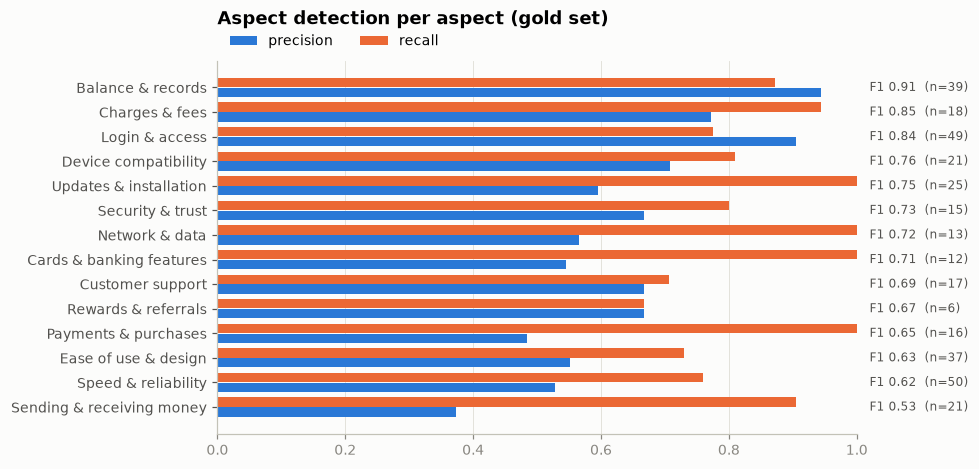

,gold,predicted,precision,recall,f1,tp,fp,fn
aspect,,,,,,,,
Sending & receiving money,21,51,0.373,0.905,0.528,19,32,2
Speed & reliability,50,72,0.528,0.760,0.623,38,34,12
Ease of use & design,37,49,0.551,0.730,0.628,27,22,10
Payments & purchases,16,33,0.485,1.000,0.653,16,17,0
Rewards & referrals,6,6,0.667,0.667,0.667,4,2,2
Customer support,17,18,0.667,0.706,0.686,12,6,5
Cards & banking features,12,22,0.545,1.000,0.706,12,10,0
Network & data,13,23,0.565,1.000,0.722,13,10,0
Security & trust,15,18,0.667,0.800,0.727,12,6,3


In [7]:
pa = per_aspect["seed + FastText expansion"]
pa = pa[pa["gold"] > 0].sort_values("f1")
pa.index = pa.index.map(full_lex.name)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
y = np.arange(len(pa))
ax.barh(y - 0.2, pa["precision"], height=0.38, color=viz.BLUE, label="precision")
ax.barh(y + 0.2, pa["recall"], height=0.38, color="#eb6834", label="recall")
for i, (n, f) in enumerate(zip(pa["gold"], pa["f1"])):
    ax.text(1.02, i, f"F1 {f:.2f}  (n={n})", va="center", fontsize=8, color=viz.INK_2)
ax.set_yticks(y, pa.index); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Aspect detection per aspect (gold set)", pad=24)
viz.save(fig, "06_detection_per_aspect")
plt.show()
pa.round(3)

In [8]:
pred = table["clean"].map(lambda c: set(full_lex.tag(c)))
err = table.assign(predicted=pred,
                   missed=[g - p for g, p in zip(table["gold_aspects"], pred)],
                   extra=[p - g for g, p in zip(table["gold_aspects"], pred)])
err[(err["missed"].str.len() > 0) | (err["extra"].str.len() > 0)][["sentence", "gold_aspects", "predicted", "missed", "extra"]].head(20)

,sentence,gold_aspects,predicted,missed,extra
3,VRob ft of the m v received vl email below,{},{transactions},{},{transactions}
7,Getting Id verification error on creating account,{login},"{login, performance}",{},{performance}
11,"Finally therz proof of payment, you could add fingerprint confirmation when paying","{login, balance}","{login, balance, payments}",{},{payments}
12,We certainly need to send proof of payment,{balance},"{balance, transactions, payments}",{},"{transactions, payments}"
13,"3 hours after I did a trans, the application allowed me to continue making transactions without asking me to relog i...",{security},"{login, updates, transactions}",{security},"{login, updates, transactions}"
15,Can't see other payments on the statement,{balance},"{balance, payments}",{},{payments}
16,"this app writes ""threats detected 1007"" whenever I try to open it",{performance},{compatibility},{performance},{compatibility}
18,"the app keeps on saying your account is locked, and when I try to request for security questions they won't come",{login},{security},{login},{security}
23,Makes transacting a lot easier and faster,{transactions},"{usability, performance, transactions}",{},"{usability, performance}"
25,Pooor has been failing to update the app,{updates},"{performance, updates}",{},{performance}


## 4. Aspect sentiment: which scope, which classifier?

In [9]:
tf = transformer_predictions()
tf_map = dict(zip(tf["key"], tf["pred"])) if tf is not None else {}
units = []
for strategy in ("sentence", "clause", "dependency"):
    u = aspect_units(table, full_lex, strategy)
    u["our model"] = model.predict(u["scope"])
    u["VADER"] = u["scope"].map(vader_label)
    u["review stars"] = u["review_label"]
    keys = u["gold_id"] + "|" + u["aspect"] + "|" + strategy
    if keys.isin(tf_map).all():
        u["transformer"] = keys.map(tf_map)
    units.append(u)
units = pd.concat(units, ignore_index=True)
methods = [m for m in ["our model", "transformer", "VADER", "review stars"] if m in units]

rows = []
for strategy, u in units.groupby("strategy", sort=False):
    u = u[u["gold_sentiment"].isin(LABELS)]
    for m in methods:
        sc = scores(u["gold_sentiment"], u[m]); lo, hi = bootstrap_ci(u["gold_sentiment"], u[m])
        rows.append({"scope": strategy, "method": m, "n": sc["n"], "accuracy": sc["accuracy"],
                     "macro_f1": sc["macro_f1"], "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                     "f1_negative": sc["f1_negative"], "f1_neutral": sc["f1_neutral"], "f1_positive": sc["f1_positive"]})
aspect_sent = pd.DataFrame(rows)
aspect_sent.to_csv(TABLES_DIR / "06_aspect_sentiment.csv", index=False)
aspect_sent.round(3)

,scope,method,n,accuracy,macro_f1,95% CI,f1_negative,f1_neutral,f1_positive
0,sentence,our model,339,0.717,0.627,"[0.572, 0.679]",0.821,0.339,0.721
1,sentence,transformer,339,0.735,0.673,"[0.618, 0.726]",0.821,0.400,0.798
2,sentence,VADER,339,0.487,0.431,"[0.380, 0.478]",0.563,0.169,0.561
3,sentence,review stars,339,0.743,0.587,"[0.528, 0.647]",0.855,0.226,0.679
4,clause,our model,339,0.737,0.642,"[0.585, 0.696]",0.834,0.349,0.743
5,clause,transformer,339,0.761,0.708,"[0.651, 0.758]",0.835,0.439,0.848
6,clause,VADER,339,0.481,0.430,"[0.383, 0.477]",0.556,0.158,0.577
7,clause,review stars,339,0.743,0.587,"[0.528, 0.647]",0.855,0.226,0.679
8,dependency,our model,339,0.637,0.562,"[0.508, 0.616]",0.738,0.311,0.638
9,dependency,transformer,339,0.575,0.575,"[0.525, 0.621]",0.657,0.341,0.726


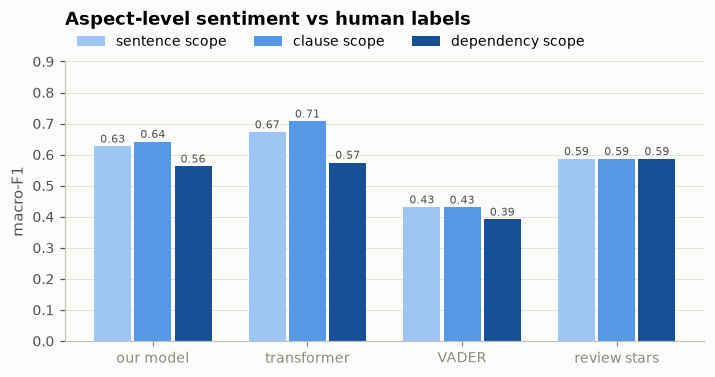

In [10]:
piv = aspect_sent.pivot(index="method", columns="scope", values="macro_f1").loc[methods, ["sentence", "clause", "dependency"]]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
colors = {"sentence": "#9ec5f4", "clause": "#5598e7", "dependency": "#184f95"}
x = np.arange(len(piv)); w = 0.26
for k, sc in enumerate(piv.columns):
    ax.bar(x + (k - 1) * w, piv[sc], w * 0.92, color=colors[sc], label=f"{sc} scope")
    for xi, v in zip(x + (k - 1) * w, piv[sc]):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=7.5, color=viz.INK_2)
ax.set_xticks(x, piv.index); ax.set_ylim(0, max(0.9, piv.values.max() + 0.1)); ax.set_ylabel("macro-F1")
ax.grid(axis="x", visible=False); ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Aspect-level sentiment vs human labels", pad=24)
viz.save(fig, "06_aspect_sentiment")
plt.show()

In [11]:
best_scope = piv.loc["our model"].idxmax()
u = units[(units["strategy"] == best_scope) & units["gold_sentiment"].isin(LABELS)]
by_subset = pd.DataFrame({s: {"n": len(g), "our model": scores(g["gold_sentiment"], g["our model"])["macro_f1"],
                              "review stars": scores(g["gold_sentiment"], g["review stars"])["macro_f1"],
                              "VADER": scores(g["gold_sentiment"], g["VADER"])["macro_f1"]}
                          for s, g in u.groupby("subset")}).T
print(f"best scope for our model: {best_scope}")
by_subset.round(3)

best scope for our model: clause


,n,our model,review stars,VADER
holdout,93.0,0.662,0.591,0.306
test_known,78.0,0.517,0.700,0.567
test_unseen,168.0,0.685,0.506,0.412


In [12]:
# McNemar on the clause scope
from absa.evaluate import mcnemar
u = units[(units["strategy"] == "clause") & units["gold_sentiment"].isin(LABELS)]
pd.DataFrame({m: mcnemar(u["gold_sentiment"], u["our model"], u[m]) for m in methods if m != "our model"}).T

,only_a_correct,only_b_correct,p_value
transformer,61.0,69.0,5.394196e-01
VADER,130.0,43.0,2.334125e-11
review stars,55.0,57.0,9.247751e-01


## 5. End-to-end (aspect, sentiment) pairs

In [13]:
e2e = {}
for strategy in ("sentence", "clause", "dependency"):
    an = ABSAnalyzer(model=model, lexicon=full_lex, strategy=strategy)
    e2e[strategy] = end_to_end(table, an)
e2e = pd.DataFrame(e2e).T[["precision", "recall", "f1", "tp", "fp", "fn"]]
e2e.to_csv(TABLES_DIR / "06_end_to_end.csv")
e2e.round(3)

,precision,recall,f1,tp,fp,fn
sentence,0.448,0.605,0.514,205.0,253.0,134.0
clause,0.463,0.625,0.532,212.0,246.0,127.0
dependency,0.389,0.525,0.447,178.0,280.0,161.0


## 6. Where aspect-level analysis beats the star rating

In [14]:
an = ABSAnalyzer(model=model, lexicon=full_lex, strategy=best_scope)
mixed = table[table["sentence_sentiment"] == "mixed"]
show = []
for r in mixed.itertuples():
    got = {(o.aspect, o.sentiment) for o in an.analyse(r.sentence) if o.aspect != "general"}
    show.append({"sentence": r.sentence, "human": sorted(r.gold_pairs), "pipeline": sorted(got),
                 "review stars": r.review_label})
pd.DataFrame(show).head(12)

,sentence,human,pipeline,review stars
0,"Finally therz proof of payment, you could add fingerprint confirmation when paying","[(balance, positive), (login, neutral)]","[(balance, neutral), (login, neutral), (payments, neutral)]",positive
1,Good interface but lacks in App help services and I can't use my money🤦🏾,"[(support, negative), (transactions, negative), (usability, positive)]","[(usability, neutral)]",negative
2,hmmm panhau dze limit apa ndanzwa nema withdraw limits blah blah do better guys asi the app is quite fast zvaro paku...,"[(performance, positive), (transactions, negative)]","[(performance, positive), (transactions, neutral)]",negative
3,easy to use too bad u gotta have data all the time,"[(connectivity, negative), (usability, positive)]","[(connectivity, neutral), (usability, neutral)]",positive
4,"Even though the App is excellent and fast, i am very very upset 😔 because it only works using Data, 1st: how am i su...","[(connectivity, negative), (performance, positive)]","[(connectivity, negative), (payments, negative), (performance, negative), (transactions, negative)]",negative
5,"The app is good nice to see an update, however the security policy blocks screenshots","[(balance, negative), (updates, positive)]","[(balance, neutral), (security, neutral), (updates, positive)]",positive
6,I'm in favor of ZB bank because the stuff makes it a point that you issue is solved satisfactory for example i had a...,"[(fees, negative), (support, positive)]","[(cards, negative), (fees, negative)]",positive
7,This app is good and easy to use but problem is some options had not functional exactly what they mentioned: especia...,"[(payments, negative), (usability, positive)]","[(payments, neutral), (support, neutral), (usability, positive)]",positive
8,am using a Samsung with ample cores and ram),"[(login, negative), (support, positive), (usability, positive)]","[(compatibility, negative)]",positive
9,The new 2021 may update covers all issues Well done for being able to share proof of payment Can the app be able to ...,"[(balance, positive), (transactions, neutral), (updates, positive)]","[(balance, neutral), (payments, neutral), (transactions, neutral), (updates, neutral)]",positive


## 7. What the gold set shows

Star labels are noisy at sentence level. They agree with the human label for only 74% of single-sentiment
sentences; 23 sentences a human called negative come from positively-rated reviews. This caps how well any model
trained on stars can score, and it is why this evaluation exists.

Aspect detection: high recall, modest precision. Recall 0.84 (0.68 on the purely random sample, the unbiased
estimate) and precision 0.62, F1 0.71. The lexicon finds most aspects a person finds but over-tags:
*Sending & receiving money* (precision 0.37: "send proof of payment" is about records), *Speed & reliability* and
*Ease of use* ("easy and fast" usually got one main aspect from the annotator). Part of the gap is annotation
granularity: the annotator usually named the *main* aspect, while the lexicon tags every matching word. Precise
aspects are those with specific vocabulary: Balance & records (F1 0.91), Charges & fees (0.85), Login & access (0.84).
The FastText expansion adds a little recall (from 0.829 to 0.838) without hurting precision.

Aspect sentiment: our model beats the star and VADER baselines; the transformer scores highest. With the
clause scope our model reaches macro-F1 0.642 [0.585, 0.696], vs 0.587 for giving every aspect its review's
stars and 0.43 for VADER. The pretrained transformer reaches 0.708 [0.651, 0.758], mostly through better
neutral and positive F1. The intervals overlap and McNemar's test finds no significant difference (p = 0.54), but the
direction makes sense: the transformer was trained on short, sentence-level tweets, exactly the length of a clause,
while our model learned from whole-review star ratings (the fee-clause weakness above). Our model stays the default
because it is 500 times smaller, interpretable and needs no PyTorch; the transformer is the natural upgrade for the
sentiment step.
Splitting at contrast words (*but, however, asi*) helps over whole sentences (0.627). The clause scope drops the
leading contrast word before scoring ("but the charges are too high" -> "the charges are too high"), because in
training "but" mostly appears in mixed reviews that still got 4-5 stars and pulls a clause towards positive. This rule
was decided from hand-made test sentences and then checked once here: it raised the clause score from 0.634 to 0.642.

Dependency scope did not help. Cutting each aspect's opinion out of the dependency parse scored
*worse* (0.562). The parser is trained on edited English; on cleaned, unpunctuated phone text it often attaches
words to the wrong clause, and the scope loses the sentiment words ("it sends the otp but"). The final pipeline
therefore uses the clause scope (chosen here and read by notebook 07 and the app from `06_summary.json`).

By test set: the model beats the star baseline clearly on unseen brands (0.69 vs 0.51) and in-domain (0.66 vs 0.59),
but not on the Super App (0.52 vs 0.70, n = 78, wide intervals), where many complaint sentences sit in short 1-star
reviews whose stars already say everything.

End-to-end, a complete (aspect, sentiment) pair is right with F1 0.53: both parts must be correct, so detection
over-tagging and sentiment errors multiply.

In [15]:
summary = {
    "n_sentences": int(len(table)), "n_aspect_pairs": int(len(units) // 3),
    "star_vs_human_agreement": float(agree),
    "detection": detection.round(4).to_dict(orient="index"),
    "aspect_sentiment_best_scope": best_scope,
    "aspect_sentiment": aspect_sent.round(4).to_dict(orient="records"),
    "end_to_end": e2e.round(4).to_dict(orient="index"),
}
json.dump(summary, open(TABLES_DIR / "06_summary.json", "w"), indent=2)
print(json.dumps({k: v for k, v in summary.items() if k in ("n_sentences", "star_vs_human_agreement",
                                                          "aspect_sentiment_best_scope")}, indent=2))

{
  "n_sentences": 250,
  "star_vs_human_agreement": 0.7352941176470589,
  "aspect_sentiment_best_scope": "clause"
}
